# ***Importing Libraries***

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [29]:
vocab_size = 10000
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.imdb.load_data(num_words=vocab_size)

In [30]:
print(X_train_full.shape, y_train_full.shape)
print(X_test.shape, y_test.shape)

(25000,) (25000,)
(25000,) (25000,)


In [31]:
X_train_full[0][:15]

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4]

In [32]:
word_index = keras.datasets.imdb.get_word_index()
index_word = {i + 3: w for w, i in word_index.items()}
index_word.update({0: '<PAD>', 1: '<START>', 2: '<UNK>'})

print(' '.join(index_word.get(i, '?') for i in X_train_full[0]))
print('Label:', y_train_full[0])

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

In [33]:
lengths = pd.Series([len(x) for x in X_train_full])
lengths.describe()

,0
count,25000.000000
mean,238.713640
std,176.497204
min,11.000000
25%,130.000000
50%,178.000000
75%,291.000000
max,2494.000000


In [34]:
(lengths > 200).mean() * 100

np.float64(42.708)

In [35]:
pd.Series(y_train_full).map({0: 'Negative', 1: 'Positive'}).value_counts(normalize=True) * 100

,proportion
Positive,50.0
Negative,50.0


# ***Data Visualization***

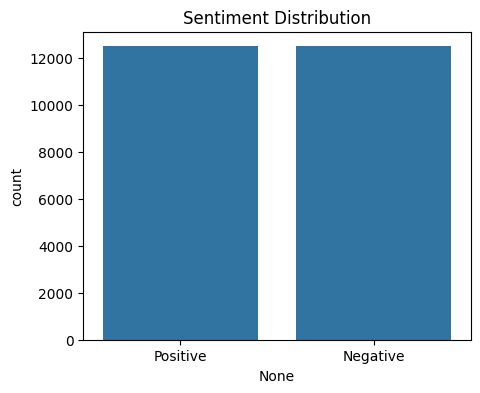

In [36]:
sentiment = pd.Series(y_train_full).map({0: 'Negative', 1: 'Positive'})

plt.figure(figsize=(5, 4))
sns.countplot(x=sentiment)
plt.title('Sentiment Distribution')
plt.show()

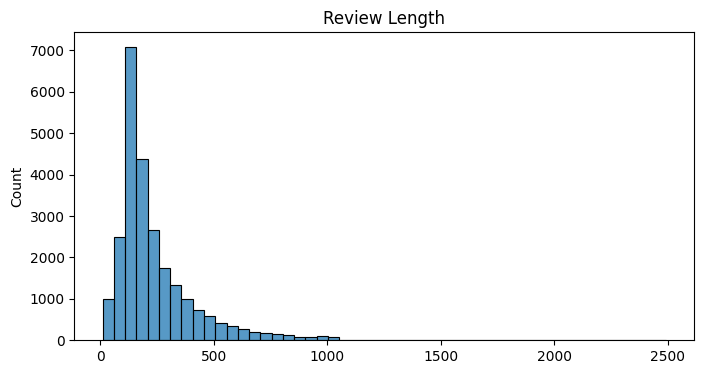

In [37]:
plt.figure(figsize=(8, 4))
sns.histplot(lengths, bins=50)
plt.title('Review Length')
plt.show()

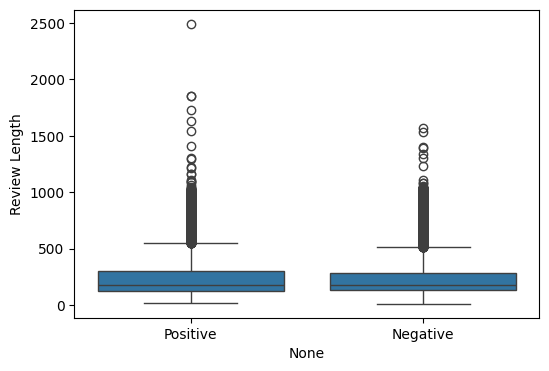

In [38]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=sentiment, y=lengths)
plt.ylabel('Review Length')
plt.show()

# ***Data Preprocessing***

In [39]:
maxlen = 200

X_train_full = keras.utils.pad_sequences(X_train_full, maxlen=maxlen)
X_test = keras.utils.pad_sequences(X_test, maxlen=maxlen)
X_train_full.shape

(25000, 200)

In [40]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(22500, 200) (2500, 200) (25000, 200)


# ***Simple RNN Model***

In [41]:
rnn_model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(vocab_size, 32),
    layers.SimpleRNN(32),
    layers.Dense(1, activation='sigmoid')
])

rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
rnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,113 (1.23 MB)

 Trainable params: 322,113 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

rnn_history = rnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=128, callbacks=[early_stop], verbose=2)

Epoch 1/15
176/176 - 8s - 43ms/step - accuracy: 0.6045 - loss: 0.6699 - val_accuracy: 0.6988 - val_loss: 0.6243
Epoch 2/15
176/176 - 3s - 18ms/step - accuracy: 0.8003 - loss: 0.4633 - val_accuracy: 0.8228 - val_loss: 0.4087
Epoch 3/15
176/176 - 3s - 16ms/step - accuracy: 0.8556 - loss: 0.3430 - val_accuracy: 0.7468 - val_loss: 0.5083
Epoch 4/15
176/176 - 3s - 16ms/step - accuracy: 0.8983 - loss: 0.2589 - val_accuracy: 0.8120 - val_loss: 0.4304
Epoch 5/15
176/176 - 3s - 18ms/step - accuracy: 0.9473 - loss: 0.1561 - val_accuracy: 0.8104 - val_loss: 0.4724


# ***LSTM Model***

In [43]:
lstm_model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(vocab_size, 32),
    layers.LSTM(32),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lstm_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,353 (1.25 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

In [44]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

lstm_history = lstm_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=128, callbacks=[early_stop], verbose=2)

Epoch 1/15
176/176 - 4s - 22ms/step - accuracy: 0.7524 - loss: 0.4835 - val_accuracy: 0.8548 - val_loss: 0.3415
Epoch 2/15
176/176 - 2s - 11ms/step - accuracy: 0.8922 - loss: 0.2717 - val_accuracy: 0.8824 - val_loss: 0.3108
Epoch 3/15
176/176 - 2s - 11ms/step - accuracy: 0.9137 - loss: 0.2271 - val_accuracy: 0.8720 - val_loss: 0.3308
Epoch 4/15
176/176 - 2s - 11ms/step - accuracy: 0.9273 - loss: 0.1970 - val_accuracy: 0.8708 - val_loss: 0.3522
Epoch 5/15
176/176 - 2s - 11ms/step - accuracy: 0.9156 - loss: 0.2147 - val_accuracy: 0.8360 - val_loss: 0.4492


# ***GRU Model***

In [45]:
gru_model = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(vocab_size, 32),
    layers.GRU(32),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

gru_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gru_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,369 (1.24 MB)

 Trainable params: 326,369 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

gru_history = gru_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=128, callbacks=[early_stop], verbose=2)

Epoch 1/15
176/176 - 4s - 21ms/step - accuracy: 0.7315 - loss: 0.5045 - val_accuracy: 0.8548 - val_loss: 0.3391
Epoch 2/15
176/176 - 2s - 11ms/step - accuracy: 0.8854 - loss: 0.2822 - val_accuracy: 0.8324 - val_loss: 0.3973
Epoch 3/15
176/176 - 2s - 11ms/step - accuracy: 0.9110 - loss: 0.2329 - val_accuracy: 0.8408 - val_loss: 0.4015
Epoch 4/15
176/176 - 2s - 11ms/step - accuracy: 0.9185 - loss: 0.2133 - val_accuracy: 0.8488 - val_loss: 0.3459


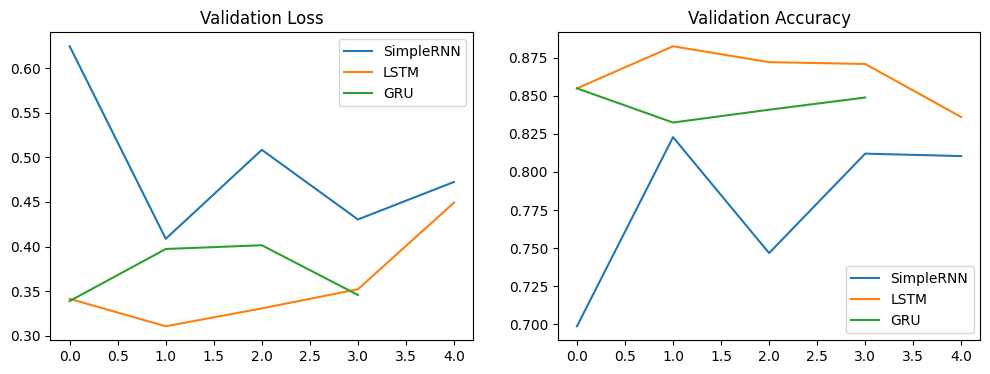

In [47]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(rnn_history.history['val_loss'], label='SimpleRNN')
plt.plot(lstm_history.history['val_loss'], label='LSTM')
plt.plot(gru_history.history['val_loss'], label='GRU')
plt.title('Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(rnn_history.history['val_accuracy'], label='SimpleRNN')
plt.plot(lstm_history.history['val_accuracy'], label='LSTM')
plt.plot(gru_history.history['val_accuracy'], label='GRU')
plt.title('Validation Accuracy')
plt.legend()

plt.show()

# ***Evaluating the LSTM***

In [48]:
y_prob_lstm = lstm_model.predict(X_test, verbose=0).ravel()
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int)

print(classification_report(y_test, y_pred_lstm, target_names=['Negative', 'Positive']))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lstm))

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87     12500
    Positive       0.86      0.88      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000

ROC-AUC: 0.9436149215999999


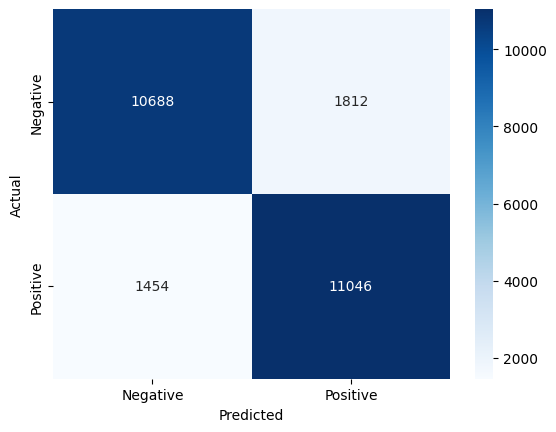

In [49]:
cm = confusion_matrix(y_test, y_pred_lstm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [50]:
review = "this movie was great and the acting was amazing"

seq = [1]
for w in review.split():
    i = word_index.get(w, -1) + 3
    seq.append(i if i < vocab_size else 2)

seq = keras.utils.pad_sequences([seq], maxlen=maxlen)
prob = lstm_model.predict(seq, verbose=0)[0][0]
print(prob, 'Positive' if prob >= 0.5 else 'Negative')

0.745856 Positive


# ***Model Comparison***

In [51]:
y_prob_rnn = rnn_model.predict(X_test, verbose=0).ravel()
y_prob_gru = gru_model.predict(X_test, verbose=0).ravel()

results = []
for name, y_prob in [("SimpleRNN", y_prob_rnn), ("LSTM", y_prob_lstm), ("GRU", y_prob_gru)]:
    y_pred = (y_prob >= 0.5).astype(int)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="ROC-AUC", ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LSTM,0.86936,0.859076,0.88368,0.871204,0.943615
1,GRU,0.85120,0.831972,0.88016,0.855388,0.928494
2,SimpleRNN,0.81944,0.835377,0.79568,0.815045,0.892435


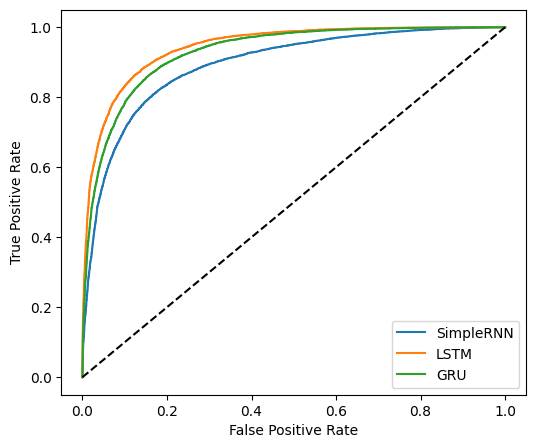

In [52]:
plt.figure(figsize=(6, 5))

for name, y_prob in [("SimpleRNN", y_prob_rnn), ("LSTM", y_prob_lstm), ("GRU", y_prob_gru)]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

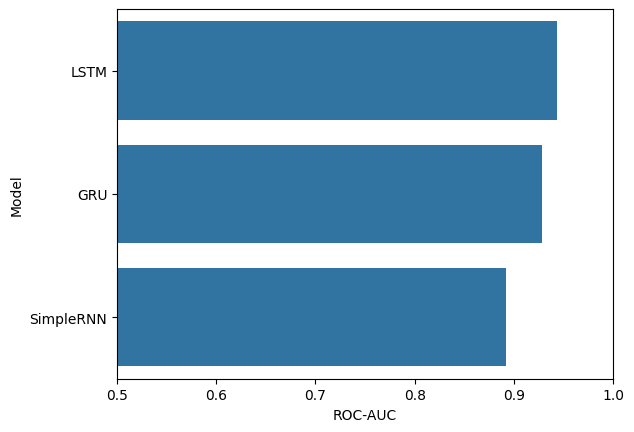

In [53]:
sns.barplot(x="ROC-AUC", y="Model", data=results_df)
plt.xlim(0.5, 1.0)
plt.show()